# Trabajo Práctico  - Calibración y Pose de la Cámara

## Resolución

## GRUPO: EMROVEVI

# Integrantes
* Vera Roux, LU: 326/25
* Emma Victoria Tripaldi, LU: 287/25
* María Rosario Cabrera, LU: 659/25
* Victoria Florencia Lima, LU: 101/25

In [19]:
import numpy as np
from alc import *
import pandas as pd
import matplotlib.pyplot as plt
import cv2

import os

def buscar_ruta(*partes):
    """Busca un archivo de datos por su nombre.
    Recibe: las partes de la ruta segun el template (ej. "heli", "row_00248.png").
    Devuelve: la ruta del archivo, buscandolo primero junto al notebook y despues en
    las subcarpetas (hasta 3 niveles). Si no lo encuentra, devuelve la ruta del template."""
    nombre = partes[-1]
    pendientes = [(".", 0)]
    while len(pendientes) > 0:
        carpeta, nivel = pendientes.pop(0)
        try:
            contenido = os.listdir(carpeta)
        except OSError:
            continue                                  # no es una carpeta o no se puede leer
        if nombre in contenido:
            return os.path.join(carpeta, nombre)
        if nivel < 3:
            for elemento in contenido:
                if elemento[0] != ".":
                    pendientes.append((os.path.join(carpeta, elemento), nivel + 1))
    return os.path.join(*partes)


### Ejercicio 1 - DLT ecuaciones formales

Siendo $Q\in \mathbb{R}^{2n\times 12}$, ¿qué rango debe tener para asegurar una solución no nula única a menos de un factor de escala? ¿Cuántos puntos, como mínimo, aseguran la solución y qué condición deben cumplir?

Encontrar el vector $\mathbf{m}$ que resuelve la minimización de la ecuación 6.

**a)** Para $n$ puntos, el sistema de la ecuación (6) es $Q\,\mathbf{m}=\mathbf{0}$, con $Q\in\mathbb{R}^{2n\times 12}$ y $\mathbf{m}\in\mathbb{R}^{12}$ (las 12 entradas de $M\in\mathbb{R}^{3\times4}$). Cada punto aporta dos filas, una por cada coordenada de su pixel $(u_i,v_i)$.

**Rango necesario:** buscamos $\mathbf{m}\neq 0$, así que $\mathrm{Nu}(Q)\neq\{0\}$. Que la solución sea única a menos de un factor de escala significa que $\mathrm{Nu}(Q)$ es una recta, es decir $\dim\mathrm{Nu}(Q)=1$. Por el teorema de la dimensión:

$$\mathrm{rg}(Q)=12-\dim\mathrm{Nu}(Q)=12-1=11 .$$

**Cantidad mínima de puntos:** como $\mathrm{rg}(Q)\le 2n$, se necesita $2n\ge 11$, o sea $n\ge 5{,}5$. Por lo tanto hacen falta al menos $n=6$ puntos, que dan 12 ecuaciones para 11 grados de libertad (con 5 puntos hay solo 10 ecuaciones y $\dim\mathrm{Nu}(Q)\ge 2$).

**Condición sobre los puntos:** con $n=6$ la matriz $Q$ tiene 12 filas y debe tener rango 11, de modo que exista exactamente una dependencia lineal entre ellas (la que corresponde a $\mathbf{m}$). Esto se cumple si los puntos $P_i$ no son coplanares. Por eso la calibración con puntos 3D exige una mira no plana, y el caso coplanar se trata aparte (ejercicio 3).

Decir que la solución es única "a menos de un factor de escala" significa que lo que queda determinado es la dirección $\langle\mathbf{m}\rangle$, no un vector particular: $\mathbf{m}$ y $c\,\mathbf{m}$ ($c\neq0$) representan la misma proyección, porque $\lambda$ es libre. 

**b)** Encontrar el vector m que resuelve la minimización de la ecuación 8

Con datos reales no existe $\mathbf{m}\neq 0$ con $Q\mathbf{m}=0$ exactamente, así que se resuelve

$$\min_{\|\mathbf{m}\|=1}\ \|Q\mathbf{m}\|^2 .$$

Desarrollando la norma:

$$\|Q\mathbf{m}\|^2=(Q\mathbf{m})^\top(Q\mathbf{m})=\mathbf{m}^\top Q^\top Q\,\mathbf{m}.$$

**Autovalores de $Q^\top Q$:** La matriz $Q^\top Q\in\mathbb{R}^{12\times12}$ es simétrica y semidefinida positiva ($\mathbf{x}^\top Q^\top Q\,\mathbf{x}=\|Q\mathbf{x}\|^2\ge0$). Por el teorema espectral tiene autovalores reales $0\le\lambda_1\le\lambda_2\le\dots\le\lambda_{12}$ y autovectores $\mathbf{v}_1,\dots,\mathbf{v}_{12}$ ortonormales, con $Q^\top Q\,\mathbf{v}_i=\lambda_i\mathbf{v}_i$.

**Escribimos $\mathbf{m}$ en esa base:** Como los $\mathbf{v}_i$ forman una base ortonormal de $\mathbb{R}^{12}$, existen escalares $c_i$ tales que

$$\mathbf{m}=\sum_{i=1}^{12}c_i\,\mathbf{v}_i,\qquad \|\mathbf{m}\|^2=1\ \Longrightarrow\ \sum_{i=1}^{12}c_i^2=1 .$$

Aplicando $Q^\top Q$:

$$Q^\top Q\,\mathbf{m}=\sum_i c_i\,Q^\top Q\,\mathbf{v}_i=\sum_i c_i\lambda_i\,\mathbf{v}_i,$$

y usando la ortonormalidad:

$$\|Q\mathbf{m}\|^2=\mathbf{m}^\top Q^\top Q\,\mathbf{m}=\sum_{i=1}^{12}\lambda_i\,c_i^2\ \ge\ \lambda_1\sum_{i=1}^{12}c_i^2=\lambda_1 .$$

**Conclusión:** La cota inferior $\lambda_1$ se alcanza con $c_1=\pm1$ y $c_i=0$ para $i>1$, es decir, con $\mathbf{m}=\pm\mathbf{v}_1$. Si $\lambda_1$ es un autovalor simple, ese es el único minimizador (salvo el signo).

Por lo tanto, **$\mathbf{m}$ es el autovector de norma 1 de $Q^\top Q$ asociado a su menor autovalor $\lambda_1$**. Si $Q=U\Sigma V^\top$ es una SVD, entonces $Q^\top Q=V\Sigma^2V^\top$, por lo que los autovalores de $Q^\top Q$ son $\sigma_i^2$ y $\mathbf{m}$ es la columna de $V$ asociada al menor valor singular $\sigma_{\min}$. El valor mínimo del residuo es $\|Q\mathbf{m}\|=\sigma_{\min}$, que vale 0 si los datos son exactos. El signo de $\mathbf{m}$ no está determinado, porque $\mathbf{m}$ y $-\mathbf{m}$ dan la misma proyección.

### Ejercicio 2 - Calibración con puntos 3D

a) Utilizando los datos de la carpeta $\texttt{calib/3d}$ calcular $\mathbf{R}$,  $\mathbf{t}$ y $\mathbf{K}$.

Calcular un nuevo set de parámetros para 

b) $\alpha_u = \alpha_v$ 

c) $K_{12}=0$



In [20]:
# a) Trabajamos con imágenes 1 y 50

det_corners = np.loadtxt(os.path.join("calib", "3d", "detected_corners.txt"))
imagen_1 = det_corners[0,:]
imagen_50 = det_corners[49,:]

# En la vida real tenemos un solo objeto, con 12 corners detectadas
real_corners = np.loadtxt(os.path.join("calib", "3d", "p_W_corners.txt"),delimiter=',')
objetos = real_corners

# Proceso para imagen 1
Q_imagen_1 = obtenerQ3d(imagen_1, real_corners)

# Proceso para imagen 50
Q_imagen_50 = obtenerQ3d(imagen_50, real_corners)

M_imagen_1 = resolverDLT3D(Q_imagen_1)
M_imagen_50 = resolverDLT3D(Q_imagen_50)

R_imagen_1, t_imagen_1, K_imagen_1 = devolverMatricesCalibracion3D(M_imagen_1)
R_imagen_50, t_imagen_50, K_imagen_50 = devolverMatricesCalibracion3D(M_imagen_50)

print("Imagen 1")
print("R:",R_imagen_1)
print("t:",t_imagen_1)
print("K:",K_imagen_1)

print("Imagen 50")
print("R:",R_imagen_50)
print("t:",t_imagen_50)
print("K:",K_imagen_50)

Imagen 1
R: [[-0.618213   -0.12921397  0.77531699]
 [ 0.35508353 -0.92591643  0.12881947]
 [-0.70123346 -0.35494017 -0.61829533]]
t: [-15.61437319 -10.05363346 -40.59128893]
K: [[ 5.36573011e-02 -1.97005637e-06  4.46558642e-02]
 [ 0.00000000e+00  5.34941903e-02  3.23628948e-02]
 [ 0.00000000e+00  0.00000000e+00  1.25997555e-04]]
Imagen 50
R: [[-0.55592054 -0.11320881  0.82349021]
 [ 0.3284675  -0.93997304  0.09251913]
 [-0.76358461 -0.32192306 -0.55973573]]
t: [-15.58660349 -10.34831286 -41.96162141]
K: [[ 0.05328187 -0.00020874  0.04347793]
 [ 0.          0.05308663  0.03049959]
 [ 0.          0.          0.0001224 ]]


In [21]:
# b) Ahora le pasamos el sesgo 2, αu = αv

R_imagen_1_s2, t_imagen_1_s2, K_imagen_1_s2 = devolverMatricesCalibracion3D(M_imagen_1, sesgo2=True)
R_imagen_50_s2, t_imagen_50_s2, K_imagen_50_s2 = devolverMatricesCalibracion3D(M_imagen_50, sesgo2=True)

print("Imagen 1 con sesgo 2")
print("R:",R_imagen_1_s2)
print("t:",t_imagen_1_s2)
print("K:",K_imagen_1_s2)

print("Imagen 50 con sesgo 2")
print("R:",R_imagen_50_s2)
print("t:",t_imagen_50_s2)
print("K:",K_imagen_50_s2)

Imagen 1 con sesgo 2
R: [[-0.618213   -0.12921397  0.77531699]
 [ 0.35508353 -0.92591643  0.12881947]
 [-0.70123346 -0.35494017 -0.61829533]]
t: [-15.61437319 -10.02307181 -40.59128893]
K: [[ 5.36573011e-02 -1.97005637e-06  4.46558642e-02]
 [ 0.00000000e+00  5.36573011e-02  3.23628948e-02]
 [ 0.00000000e+00  0.00000000e+00  1.25997555e-04]]
Imagen 50 con sesgo 2
R: [[-0.55592054 -0.11320881  0.82349021]
 [ 0.3284675  -0.93997304  0.09251913]
 [-0.76358461 -0.32192306 -0.55973573]]
t: [-15.58660349 -10.31039229 -41.96162141]
K: [[ 0.05328187 -0.00020874  0.04347793]
 [ 0.          0.05328187  0.03049959]
 [ 0.          0.          0.0001224 ]]


In [22]:
# c) Ahora le pasamos el sesgo 1, K[0][1] = 0

R_imagen_1_s1, t_imagen_1_s1, K_imagen_1_s1 = devolverMatricesCalibracion3D(M_imagen_1, sesgo1=True)
R_imagen_50_s1, t_imagen_50_s1, K_imagen_50_s1 = devolverMatricesCalibracion3D(M_imagen_50, sesgo1=True)

print("Imagen 1 con sesgo 1")
print("R:",R_imagen_1_s1)
print("t:",t_imagen_1_s1)
print("K:",K_imagen_1_s1)

print("Imagen 50 con sesgo 1")
print("R:",R_imagen_50_s1)
print("t:",t_imagen_50_s1)
print("K:",K_imagen_50_s1)

Imagen 1 con sesgo 1
R: [[-0.618213   -0.12921397  0.77531699]
 [ 0.35508353 -0.92591643  0.12881947]
 [-0.70123346 -0.35494017 -0.61829533]]
t: [-15.61437319 -10.05363346 -40.59128893]
K: [[0.0536573  0.         0.04465586]
 [0.         0.05349419 0.03236289]
 [0.         0.         0.000126  ]]
Imagen 50 con sesgo 1
R: [[-0.55592054 -0.11320881  0.82349021]
 [ 0.3284675  -0.93997304  0.09251913]
 [-0.76358461 -0.32192306 -0.55973573]]
t: [-15.58660349 -10.34831286 -41.96162141]
K: [[0.05328187 0.         0.04347793]
 [0.         0.05308663 0.03049959]
 [0.         0.         0.0001224 ]]


### Ejercicio 3 - Calibración con puntos coplanares

Resolver la calibración para el caso de puntos coplanares, trabajando sobre los datos de la carpeta $\texttt{calib/coplanar}$ con las imágenes $\texttt{Im\_R\_1.png}$ a $\texttt{Im\_R\_20.png}$.


a) Obtener la matriz $\mathbf{K}$

b) Encontrar la pose de $\texttt{Im\_R\_1.png}$, $\texttt{Im\_R\_10.png}$ y $\texttt{Im\_R\_20.png}$.

**a)** Para $n$ puntos, el sistema de la ecuación (11) es $Q\,\mathbf{h}=\mathbf{0}$, con $Q\in\mathbb{R}^{2n\times 9}$ y $\mathbf{h}\in\mathbb{R}^{9}$ (las 9 entradas de $H$).

Buscamos una solución no nula, así que $\mathrm{Nu}(Q)\neq\{\mathbf{0}\}$. Que sea única a menos de un factor de escala significa que $\dim\mathrm{Nu}(Q)=1$.

Por el teorema de la dimensión:

$$\mathrm{rg}(Q)=9-\dim\mathrm{Nu}(Q)=9-1=\mathbf{8}.$$


In [23]:
# Obtenemos las 77 esquinas (u,v) de las 20 imágenes

ruta = buscar_ruta("calib", "coplanar", "coordenadas_esquinas.csv")
coordenadas_esquinas_ajedrez = pd.read_csv(ruta)
imgPts_ajedrez = np.array(coordenadas_esquinas_ajedrez)


patron = (11, 7)
square_size = 3.0

# Calculamos los U,V para cada una de las esquinas

objPts_ajedrez = []

for fila in range(patron[1]):       # 7 filas
    for columna in range(patron[0]):  # 11 columnas
        U = columna * square_size
        V = fila * square_size
        W = 0.0

        objPts_ajedrez.append([U, V, W])

objPts_ajedrez = np.array(objPts_ajedrez)

Hlst_ajedrez = []

k=0
# Como hay 77 esquinas por tablero y 20 imágenes, en total hay 1540 esquinas
# Saltamos de a 77 para pasar de una imagen a otra
while(k<1540): 

    aux = imgPts_ajedrez[k:k+77,2:4]
    aux = np.array(aux)
    
    Q_imagen_i = obtenerQ2d(aux, objPts_ajedrez)
    Hlst_ajedrez += [obtener_H(Q_imagen_i)]
    
    k +=77

A_ajedrez = armarA(Hlst_ajedrez)

K_ajedrez = calcularMatrizK2D(A_ajedrez)
print("K obtenida")
print(K_ajedrez)

K obtenida
[[733.65281884   0.         516.02770692]
 [  0.         744.50176626 295.96553528]
 [  0.           0.           1.        ]]


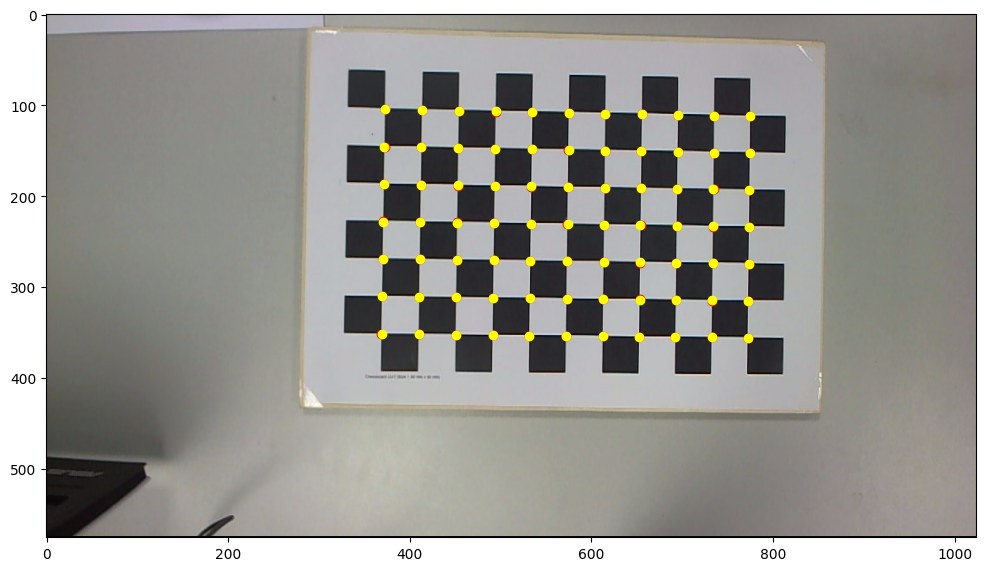

In [24]:
# Graficamos los puntos de una imagen para ver si nos dieron bien las coordenadas

img_1 = cv2.imread(os.path.join("calib", "coplanar", "Im_R_1.png"))
img_1 = img_1[:,:,::-1]
plt.figure(figsize=(12,7))
plt.imshow(img_1)

# Reproyectamos los puntos para ver que coincidan con los originales

ptos_reproyectados = []

for pto in objPts_ajedrez:
    pto = np.array([pto[0],pto[1],1])
    pto_aux = calcularAx(Hlst_ajedrez[0], pto)
    pto_reproyectado = pto_aux/pto_aux[2]
    ptos_reproyectados += [pto_reproyectado]

ptos_reproyectados = np.array(ptos_reproyectados)

plt.scatter(imgPts_ajedrez[:77, 2], imgPts_ajedrez[:77,3],c='r')
plt.scatter(ptos_reproyectados[:,0],ptos_reproyectados[:,1],c='yellow') 
plt.show()

In [25]:
# Encontramos la pose de la imagen 1

Q_im_1 = obtenerQ2d(imgPts_ajedrez[0:77,2:4], objPts_ajedrez)
H_im_1 = obtener_H(Q_im_1)
R_im_1, t_im_1 = obtenerPose2D(H_im_1, K_ajedrez)
print("Pose imagen 1") 
print(R_im_1, t_im_1)

# Encontramos la pose de la imagen 10

Q_im_10 = obtenerQ2d(imgPts_ajedrez[693:770,2:4], objPts_ajedrez)
H_im_10 = obtener_H(Q_im_10)
R_im_10, t_im_10 = obtenerPose2D(H_im_10, K_ajedrez)
print("Pose imagen 10")
print(R_im_10, t_im_10)

# Encontramos la pose de la imagen 20

Q_im_20 = obtenerQ2d(imgPts_ajedrez[1463:1540,2:4], objPts_ajedrez)
H_im_20 = obtener_H(Q_im_20)
R_im_20, t_im_20 = obtenerPose2D(H_im_20, K_ajedrez)
print("Pose imagen 20")
print(R_im_20, t_im_20)


Pose imagen 1
[[-0.99955514  0.01398846 -0.02730259]
 [-0.01219915 -0.99957233  0.00767909]
 [-0.02721586  0.00806339  0.99929831]] [ 10.58565823  13.94794195 -54.1724759 ]
Pose imagen 10
[[ 0.99739793  0.06637746 -0.02468869]
 [-0.06309699  0.98504523  0.15505988]
 [ 0.03487311 -0.15314358  0.98667029]] [ -9.31055098 -15.21408367  53.24975136]
Pose imagen 20
[[-0.99018938 -0.02566728 -0.13717902]
 [ 0.03822679 -0.9956112  -0.08378142]
 [-0.13440128 -0.08809541  0.98682482]] [  8.07368598  14.46736407 -48.1354972 ]


### Ejercicio 4 - Fútbol

a) Calcular la homografía de la cancha de futbol de la foto de $\texttt{gol-enzo.png}$. Encontrar la distancia a la que se encontraba Enzo. 
    Dibujar sobre la fotografía círculos de 1 metro de diámetro alrededor de los jugadores argentinos.

b) Calcular la homografía de la changa de fútbol de la foto $\texttt{posibleoffside.jpg}$. 
    Trazar sobre la fotografía una recta sobre el pié del jugador del equipo defensor que defina si hay fuera de juego.
    

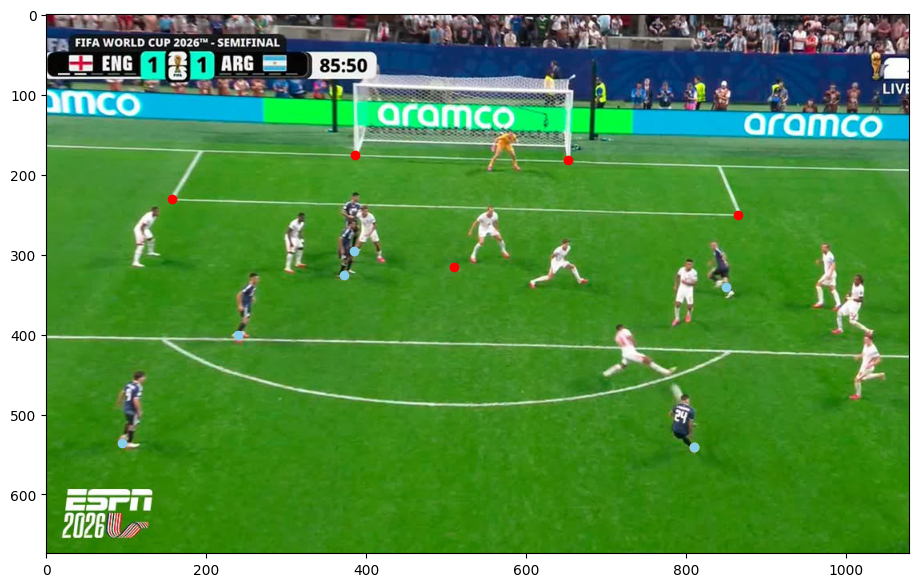

In [26]:
# a) 

# Ubicamos los puntos

img = cv2.imread(os.path.join("futbol", "test-gol-enzo.png"))
img = img[:,:,::-1]
plt.figure(figsize=(12,7))
plt.imshow(img)

#Pto penal, area chica izquierda, area chica derecha, poste izquierdo, poste derecho

puntos_img_cancha = np.array([[510,315],[157,230],[865,250],[386,175],[652,182]])
puntos_obj_cancha = np.array([[34,11],[24.84,5.5],[43.16,5.5],[30.34,0],[37.66,0]])
punto_enzo = np.array([810,540,1])

#Julian, Lautaro, Tagliafico, Cuti, McAllister

pies_argentinos = np.array([[95,535],[240,400],[372,325],[385,295],[850,340],[810,540]])

# Graficamos los pixeles calculados

plt.scatter(puntos_img_cancha[:,0], puntos_img_cancha[:,1],c='r')
plt.scatter(punto_enzo[0],punto_enzo[1],c='yellow') #punto enzo
plt.scatter(pies_argentinos[:,0],pies_argentinos[:,1],c='skyblue')
plt.show()

In [27]:
# Buscamos la posicion de Enzo en la cancha a partir de su posicion en la imagen y H inversa

Q_enzo = obtenerQ2d(puntos_img_cancha,puntos_obj_cancha)
H_enzo = obtener_H(Q_enzo)
H_enzo_inversa = inversa(H_enzo)

pos_enzo_aux = calcularAx(H_enzo_inversa, punto_enzo)

#Como obtener_H te devuelve un vector escalado, dividimos por lambda para que la ultima coordenada quede 1

pos_enzo = pos_enzo_aux / pos_enzo_aux[2]

print("Distancia de Enzo al arco en metros")
print(pos_enzo[1])

Distancia de Enzo al arco en metros
23.900007201209217


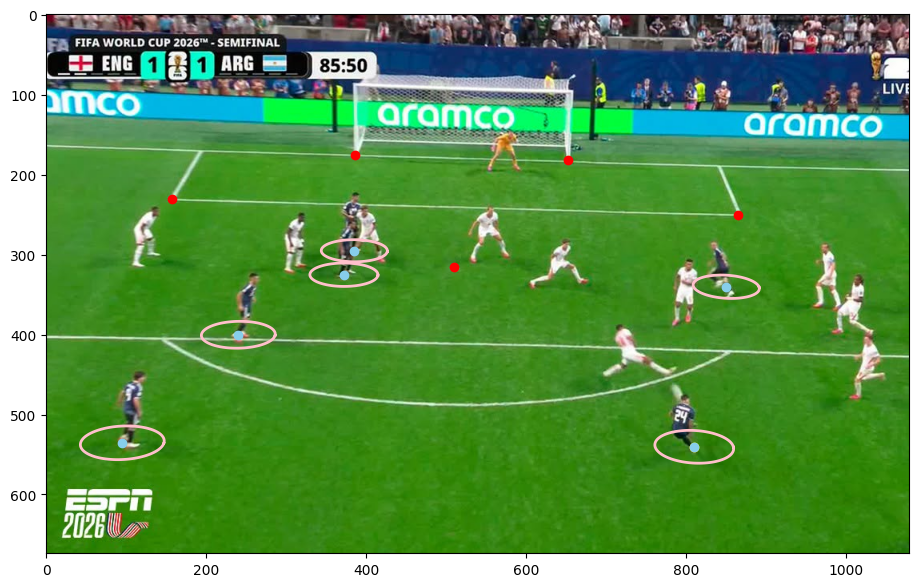

In [28]:
# Graficamos los círculos alrededor de los jugadores

img = cv2.imread(os.path.join("futbol", "test-gol-enzo.png"))
img = img[:,:,::-1]
plt.figure(figsize=(12,7))
plt.imshow(img)

for jugador in pies_argentinos:
    pos_jugador = np.array([jugador[0],jugador[1],1])
    pies_argentinos_aux = calcularAx(H_enzo_inversa,pos_jugador)
    pie_argentino_obj = pies_argentinos_aux / pies_argentinos_aux[2]

    centro_circulo = (pie_argentino_obj[0], pie_argentino_obj[1])

    puntos_circulo = circulo_de_obj_a_img(H_enzo, centro_circulo)
    plt.plot(puntos_circulo[:,0], puntos_circulo[:,1],c='pink', linewidth=2)


plt.scatter(puntos_img_cancha[:,0], puntos_img_cancha[:,1],c='r')
plt.scatter(punto_enzo[0],punto_enzo[1],c='yellow') #punto enzo
plt.scatter(pies_argentinos[:,0],pies_argentinos[:,1],c='skyblue')
plt.show()

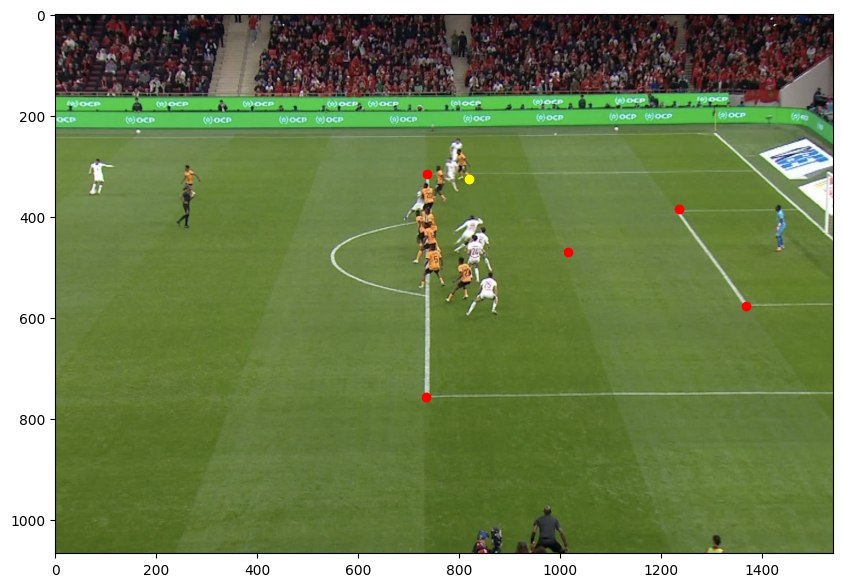

In [29]:
# b)
# Ubicamos los puntos de la cancha en la foto de offside

img = cv2.imread(os.path.join("futbol", "test-fuera-de-juego.png"))
img = img[:,:,::-1]
plt.figure(figsize=(12,7))
plt.imshow(img)

#area grande derecha, area grande izquierda, Punto penal, area chica derecha, area chica izquierda
puntos_img_offside = np.array([[734,758],[736,315],[1015,470],[1368,577],[1235,385]])
puntos_obj_offside = np.array([[54.16,16.5],[13.84,16.5],[34,11],[43.16,5.5],[24.84,5.5]])
punto_defensor = [820,325,1]

plt.scatter(puntos_img_offside[:,0], puntos_img_offside[:,1],c='r')
plt.scatter(punto_defensor[0],punto_defensor[1],c='yellow') 
plt.show()

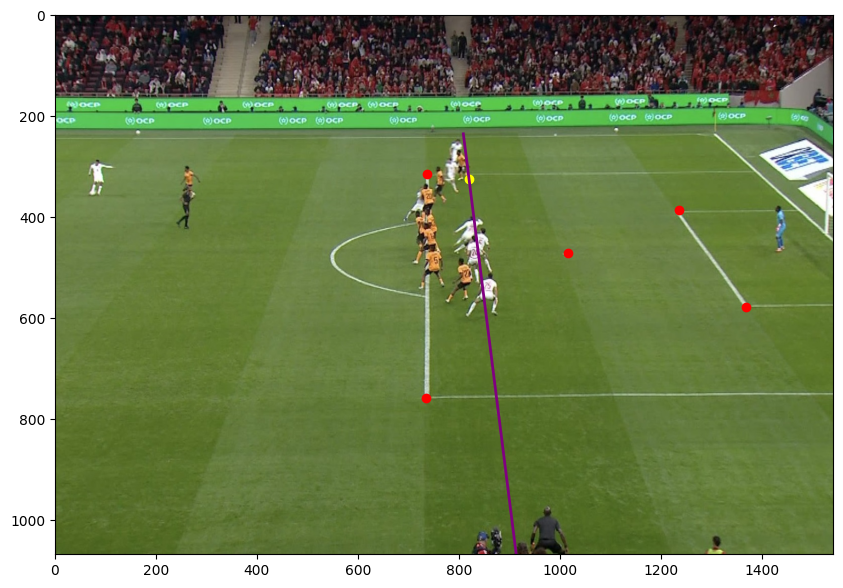

Hay offside


In [30]:
Q_offside = obtenerQ2d(puntos_img_offside,puntos_obj_offside)
H_offside = obtener_H(Q_offside)
H_offside_inversa = inversa(H_offside)
pos_defensor_aux = calcularAx(H_offside_inversa, punto_defensor) #en el estadio azteca

#Como obtener_H te devuelve un vector escalado, dividimos por lambda para que la ultima coordenada quede 1
pos_defensor = pos_defensor_aux / pos_defensor_aux[2]

#Estamos en el estadio azteca
V_defensor, U_defensor = pos_defensor[0]/pos_defensor[2], pos_defensor[1]/pos_defensor[2]
extremos_obj = [np.array([0,U_defensor,1]),np.array([68,U_defensor,1])]

#Pasamos a la img
extremos_img = []

for extremo in extremos_obj:
    X = calcularAx(H_offside, extremo)
    X =  X/X[2]

    extremos_img += [[X[0],X[1]]]
    
extremos_img = np.array(extremos_img)

img = cv2.imread(os.path.join("futbol", "test-fuera-de-juego.png"))
img = img[:,:,::-1]
plt.figure(figsize=(12,7))
plt.imshow(img)
plt.plot(extremos_img[:,0],extremos_img[:,1],c='purple',linewidth=2)
plt.scatter(puntos_img_offside[:,0], puntos_img_offside[:,1],c='r')
plt.scatter(punto_defensor[0],punto_defensor[1],c='yellow') 
plt.xlim(0,img.shape[1])
plt.ylim(img.shape[0],0)
plt.show()

print("Hay offside")

### Ejercicio 5 - Cruzando en rojo - Cálculo de velocidad

a) Calcular los parámetros intrínsecos de la cámara a partir de las diferentes vistas de la esquina y las coordenadas de los puntos en el archivo $\texttt{world\_img\_pts.csv}$

b) A partir de los puntos $\texttt{gs\_10\_09\_point\_correspondences\_v5.txt}$ calcular la pose de la cámara y reproyectar los puntos sobre la imagen $\texttt{img\_10\_18\_47\_351.jpg}$.

c) Calcular la velocidad de los dos primeros vehículos (taxi y camioneta) y de la señora de buzo rojo que cruza la calle. Graficar las velocidades en un plot temporal a lo largo de la secuencia.

* Vamos a realizar el ejercicio utilizando las funciones de puntos coplanares a pesar de que en los puntos originales hay una leve variación en Z de 0,1 m, lo que resulta insignificante con respecto a las grandes magnitudes con las que trabajamos. 

* Si quisieramos hacer Q3D con los 5 puntos dados en el CSV, tendríamos 10 filas y 12 columnas. El rango sería 11, necesitaríamos al menos 6 puntos no coplanares, pero tenemos 5. Luego nos inclinamos por la opción de Q2D despreciando la coordenada Z.


In [31]:
# a)

salguero_csv = pd.read_csv(os.path.join("salguero", "world_img_pts.csv"), sep=";")
salguero_array = salguero_csv.to_numpy(dtype=float)

objPts_salguero2d = np.zeros((5,2))
img1Pts_salguero2d = np.zeros((5,2))
img2Pts_salguero2d = np.zeros((5,2))
img3Pts_salguero2d = np.zeros((5,2))
img4Pts_salguero2d = np.zeros((5,2))

for i in range(np.shape(salguero_array)[0]):
    for j in range(1,3):
        objPts_salguero2d[i][j-1] = salguero_array[i][j]

        img1Pts_salguero2d[i][0] = salguero_array[i][4]
        img1Pts_salguero2d[i][1] = salguero_array[i][5]
        img2Pts_salguero2d[i][0] = salguero_array[i][6]
        img2Pts_salguero2d[i][1] = salguero_array[i][7]
        img3Pts_salguero2d[i][0] = salguero_array[i][8]
        img3Pts_salguero2d[i][1] = salguero_array[i][9]
        img4Pts_salguero2d[i][0] = salguero_array[i][10]
        img4Pts_salguero2d[i][1] = salguero_array[i][11]

# El DLT2D queda mal condicionado y por eso la normalización isotrópica lo arregla sin cambiar la homografía
# Esto lo hace trasladando el centro de los puntos al orígen y escalando para que la distancia media al orígen sea raíz de 2
# Normalizamos para que las columnas de Q tengan escalas comparables y el DLT2D quede bien condicionado

H1_salguero2d = obtener_H_normalizada(img1Pts_salguero2d, objPts_salguero2d)
H2_salguero2d = obtener_H_normalizada(img2Pts_salguero2d, objPts_salguero2d)
H3_salguero2d = obtener_H_normalizada(img3Pts_salguero2d, objPts_salguero2d)
H4_salguero2d = obtener_H_normalizada(img4Pts_salguero2d, objPts_salguero2d)

Hlst_salguero = [H1_salguero2d, H2_salguero2d, H3_salguero2d, H4_salguero2d]

A_salguero = armarA(Hlst_salguero)

# Como los números no salieron como esperábamos, imponemos el sesgo K[0][1] = 0 y αu = αv = f (queremos que los píxeles sean cuadrados)
# Queda una sola incógnita x = 1/f**2 que se resuelve con mínimos cuadrados

img = cv2.imread(os.path.join("salguero", "img_10_18_47_351.jpg"))

# Buscamos el centro de la imagen
u0, v0 = img.shape[1]/2 , img.shape[0] / 2
f = calcular_f(A_salguero, u0, v0)

K_salguero = np.array([[f, 0, u0], [0, f, v0], [0, 0, 1.0]])
print("Parámetros intrínsecos de la cámara (K)")
print(K_salguero)

Parámetros intrínsecos de la cámara (K)
[[3.46876312e+03 0.00000000e+00 8.00000000e+02]
 [0.00000000e+00 3.46876312e+03 6.00000000e+02]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]


Pose de la cámara
R [[-0.96448916 -0.14051673  0.00333534]
 [-0.03352477  0.19694942 -1.61721606]
 [ 0.26198617 -1.63859034 -0.19466638]]
t [  3.22177399   1.00009208 -39.04337645]


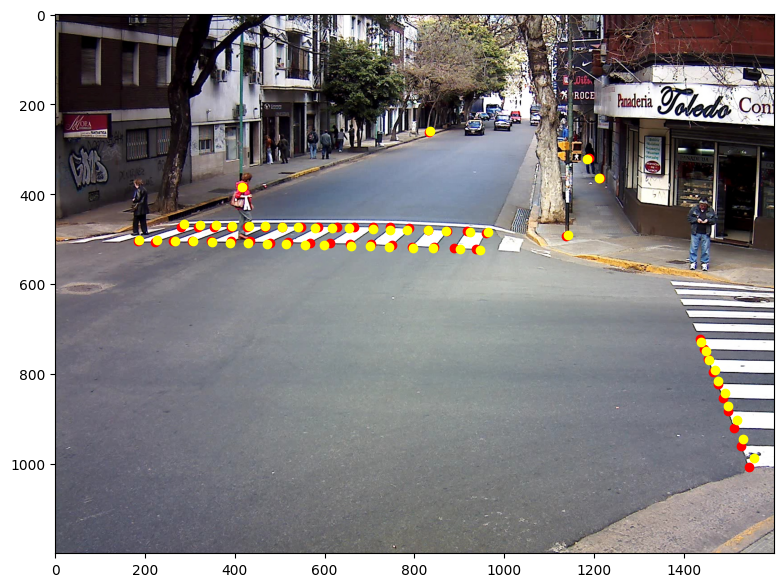

In [32]:
# b)

point_correspondences = np.loadtxt(os.path.join("salguero", "gs_10_09_point_correspondences_v5.txt"))
point_correspondences = np.array(point_correspondences)

matriz_puntos_t = trasponer(point_correspondences)

objPts_señora = np.zeros((51,2))
imgPts_señora = np.zeros((51,2))

for i in range(np.shape(matriz_puntos_t)[0]):
    objPts_señora[i][0] = matriz_puntos_t[i][1]
    objPts_señora[i][1] = matriz_puntos_t[i][2]
    imgPts_señora[i][0] = matriz_puntos_t[i][4]
    imgPts_señora[i][1] = matriz_puntos_t[i][5]

Q_señora = obtenerQ2d(imgPts_señora, objPts_señora)
H_señora = obtener_H(Q_señora)
R_señora, t_señora = obtenerPose2D(H_señora, K_salguero)

print("Pose de la cámara")
print("R",R_señora)
print("t",t_señora)

R_t_salguero = np.hstack((R_señora,t_señora.reshape(3,1)))
H_reproyectar = multiplicar_matrices(K_salguero, R_t_salguero)

ptos_reproyectados = []

for pto in objPts_señora:
    pto = np.array([pto[0],pto[1],0,1])
    pto_aux = calcularAx(H_reproyectar, pto)
    pto_reproyectado = pto_aux/pto_aux[2]
    ptos_reproyectados += [pto_reproyectado]

ptos_reproyectados = np.array(ptos_reproyectados)

# graficamos para ver que coincidan los puntos
img = cv2.imread(os.path.join("salguero", "img_10_18_47_351.jpg"))
img = img[:,:,::-1]
plt.figure(figsize=(12,7))
plt.imshow(img)

plt.scatter(matriz_puntos_t[:, 4], matriz_puntos_t[:,5],c='r')
plt.scatter(ptos_reproyectados[:,0],ptos_reproyectados[:,1],c='yellow') 
plt.show()

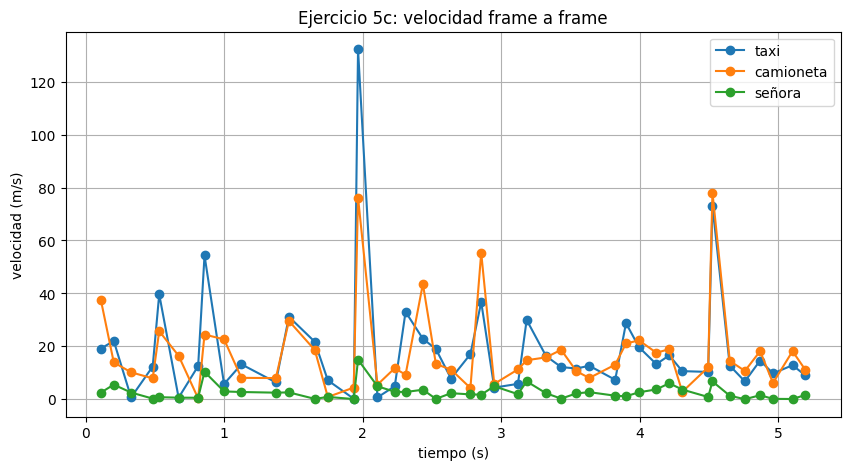

taxi 13.663128259955526 m/s = 49.1872617358399 km/h
camioneta 14.687864868497783 m/s = 52.87631352659202 km/h
señora 1.304375812465475 m/s = 4.69575292487571 km/h


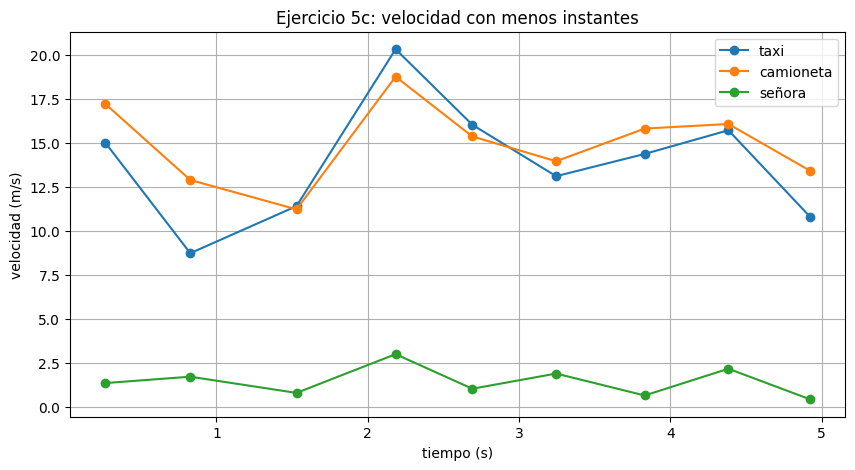

In [34]:
# c) 
clicks = np.loadtxt(buscar_ruta("clicks.csv"))

# Pasamos a segundos los instantes de cada foto en el tiempo para calcular la velocidad (van de 0 a 5 seg)

instantes_a_seg = np.array([0.0, 0.11, 0.203, 0.328, 0.484, 0.531, 0.671, 0.812, 0.858, 0.999, 1.124,
                            1.373, 1.467, 1.654, 1.748, 1.935, 1.966, 2.106, 2.231, 2.309, 2.434, 2.528,
                            2.637, 2.777, 2.855, 2.949, 3.12, 3.183, 3.323, 3.432, 3.542, 3.635, 3.822,
                            3.9, 3.994, 4.119, 4.212, 4.306, 4.493, 4.524, 4.649, 4.758, 4.868, 4.961, 5.102, 5.195])


#Usamos H
H_inv_señora = inversa(H_señora)
posiciones_señora = np.zeros((46,3,2)) #incluye taxi y camioneta

for k in range(46):
    for obj in range(3):
        pto_aux = np.array([clicks[k][2*obj], clicks[k][2*obj+1], 1.0])
        pos_señora_aux = calcularAx(H_inv_señora, pto_aux)

        posiciones_señora[k][obj] = np.array([pos_señora_aux[0]/pos_señora_aux[2],pos_señora_aux[1]/pos_señora_aux[2]])


# Hacemos la cuenta de velocidades
velocidades_taxi = []
velocidades_camioneta = []
velocidades_señora = []

for k in range(45): # llega a 45 porque usa la siguiente
    delta_x = posiciones_señora[k+1][2][0] - posiciones_señora[k][2][0]
    delta_y = posiciones_señora[k+1][2][1] - posiciones_señora[k][2][1]
    distancia = np.sqrt(delta_x**2 + delta_y**2)
    velocidades_señora.append(distancia/(instantes_a_seg[k+1] - instantes_a_seg[k]))


for k in range(45): # llega a 45 porque usa la siguiente
    delta_x = posiciones_señora[k+1][1][0] - posiciones_señora[k][1][0]
    delta_y = posiciones_señora[k+1][1][1] - posiciones_señora[k][1][1]
    distancia = np.sqrt(delta_x**2 + delta_y**2)
    velocidades_camioneta.append(distancia/(instantes_a_seg[k+1] - instantes_a_seg[k]))

for k in range(45): # llega a 45 porque usa la siguiente
    delta_x = posiciones_señora[k+1][0][0] - posiciones_señora[k][0][0]
    delta_y = posiciones_señora[k+1][0][1] - posiciones_señora[k][0][1]
    distancia = np.sqrt(delta_x**2 + delta_y**2)
    velocidades_taxi.append(distancia/(instantes_a_seg[k+1] - instantes_a_seg[k]))

plt.figure(figsize=(10, 5))
plt.plot(t[1:], velocidades_taxi, marker='o', label="taxi")
plt.plot(t[1:], velocidades_camioneta, marker='o', label="camioneta")
plt.plot(t[1:], velocidades_señora, marker='o', label="señora")
plt.xlabel("tiempo (s)")
plt.ylabel("velocidad (m/s)")
plt.title("Ejercicio 5c: velocidad frame a frame")
plt.legend()
plt.grid(True)
plt.show()

for o, nombre in [(0, "taxi"), (1, "camioneta"), (2, "señora")]:
    dx = posiciones_señora[-1][o][0] - posiciones_señora[0][o][0]
    dy = posiciones_señora[-1][o][1] - posiciones_señora[0][o][1]
    distancia = np.sqrt(dx**2 + dy**2)
    tiempo_total = instantes_a_seg[-1] - instantes_a_seg[0]
    v = distancia / tiempo_total
    print(nombre, v, "m/s =", 3.6*v, "km/h")

# Si usamos todos los frames queda mucho ruido y es dificil visualizar bien las velocidades
# Lo volvemos a hacer con menos frames

velocidades_taxi_recorte = []
velocidades_camioneta_recorte = []
velocidades_señora_recorte = []

for k in range(0,41,5): # llega a 45 porque usa la siguiente
    delta_x = posiciones_señora[k+5][2][0] - posiciones_señora[k][2][0]
    delta_y = posiciones_señora[k+5][2][1] - posiciones_señora[k][2][1]
    distancia = np.sqrt(delta_x**2 + delta_y**2)
    velocidades_señora_recorte.append(distancia/(instantes_a_seg[k+5] - instantes_a_seg[k]))


for k in range(0,41,5): # llega a 45 porque usa la siguiente
    delta_x = posiciones_señora[k+5][1][0] - posiciones_señora[k][1][0]
    delta_y = posiciones_señora[k+5][1][1] - posiciones_señora[k][1][1]
    distancia = np.sqrt(delta_x**2 + delta_y**2)
    velocidades_camioneta_recorte.append(distancia/(instantes_a_seg[k+5] - instantes_a_seg[k]))

for k in range(0,41,5): # llega a 45 porque usa la siguiente
    delta_x = posiciones_señora[k+5][0][0] - posiciones_señora[k][0][0]
    delta_y = posiciones_señora[k+5][0][1] - posiciones_señora[k][0][1]
    distancia = np.sqrt(delta_x**2 + delta_y**2)
    velocidades_taxi_recorte.append(distancia/(instantes_a_seg[k+5] - instantes_a_seg[k]))

t_recorte = []
for r in range(0,41,5):
    t_recorte.append((instantes_a_seg[r] + instantes_a_seg[r+5])/2)



plt.figure(figsize=(10, 5))
plt.plot(t_recorte, velocidades_taxi_recorte, marker='o', label="taxi")
plt.plot(t_recorte, velocidades_camioneta_recorte, marker='o', label="camioneta")
plt.plot(t_recorte, velocidades_señora_recorte, marker='o', label="señora")
plt.xlabel("tiempo (s)")
plt.ylabel("velocidad (m/s)")
plt.title("Ejercicio 5c: velocidad con menos instantes")
plt.legend()
plt.grid(True)
plt.show()

### Ejercicio 6 - Aterrizaje suave

a) Aplicar POSIT para encontrar la pose ($\mathbf{R}$ y $\mathbf{t}$) de la cámara del Drone a partir de la imagen $\texttt{row\_00248.png}$. La cámara tiene la matriz intrínseca $\mathbf{K}$. 

b) Estimar la matriz de rotación y traslación para ubicar al drone exactamente sobre la letra H y que la cámara la vea vertical (el punto blanco marca la parte superior izquierda)

[[-0.11458939 -0.9867984  -0.11444734]
 [-0.96401719  0.13827656 -0.22704725]
 [ 0.23987525  0.08431199 -0.96713564]] [-0.71757553  0.88859192  4.37455304]


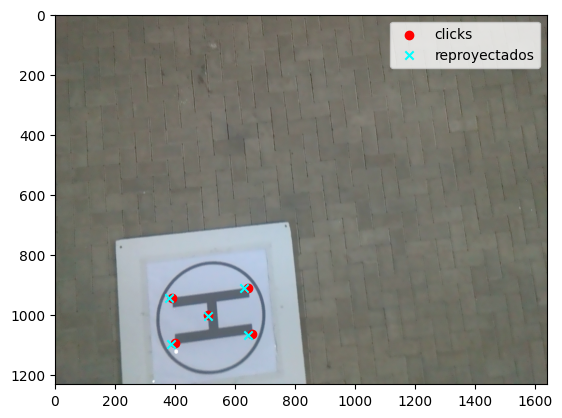

In [ ]:
K_heli = np.array([[1892.9,0.0,819.5],
          [0.0,1909.5,615.5],
          [0.0,0.0,1.0]])

imgPtos_heli = np.array([[ 509.0, 1000.0],
                [ 401.0, 1095.0],
                [ 391.0,  943.0],
                [ 643.0,  909.0],
                [ 657.0, 1063.0]])

objPtos_heli = np.array([[ 0.0,    0.0,    0.0  ],
                [-0.175,  0.3,    0.0  ],
                [ 0.175,  0.3,    0.0  ],
                [ 0.175, -0.3,    0.0  ],
                [-0.175, -0.3,    0.0  ]])

R_heli, t_heli = aplicarPOSIT(objPtos_heli, imgPtos_heli, K_heli, 50, 1e-6)

print("Pose de la cámara")
print(R_heli, t_heli)

#Graficamos los puntos sobre la imagen

import cv2
rvec, _ = cv2.Rodrigues(R_heli)
proy, _ = cv2.projectPoints(objPtos_heli, rvec, t_heli, K_heli, None)


img = cv2.imread(os.path.join("heli", "row_00248.png"))
plt.imshow(img[:, :, ::-1])
plt.scatter(imgPtos_heli[:, 0], imgPtos_heli[:, 1], c="red", label="clicks")
plt.scatter(proy[:, 0, 0], proy[:, 0, 1], c="cyan", marker="x", label="reproyectados")
plt.legend(); plt.show()

---